
# STRATUM — Linear and Ridge Regression

## Phase 3 — Step 3.2

### Objective

Develop and evaluate sensor-based virtual metrology
regression models for mean AlCu film thickness.

### Experiments

1. Linear Regression using APC measurements.
2. Linear Regression using APC and equipment metadata.
3. Ridge Regression using APC measurements.
4. Ridge Regression using APC and equipment metadata.

### Research Questions

- Do APC measurements improve thickness prediction
  compared with historical equipment averages?
- Does equipment metadata provide additional predictive value?
- Does Ridge regularisation improve validation performance?
- How does regularisation affect regression coefficients?
- Can sensor-based models reduce systematic prediction bias?

### Evaluation Protocol

- Reuse the fixed chronological and lot-aware data partitions.
- Fit all preprocessing transformations on training data.
- Compare candidate models on validation data.
- Use MAE as the primary evaluation metric.
- Reserve the final test partition for Step 3.8.
- Do not use actual metrology measurements as predictors.

### Reference Baseline

Equipment Mean Regressor:

- Validation MAE: 1.995479
- Validation RMSE: 2.444380
- Validation R2: -0.001596

In [1]:

# STEP 3.2.5 - Imports

from pathlib import Path
import sys
import json
import hashlib
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

current_dir = Path.cwd()

if (current_dir / "ml" / "linear_models.py").exists():

    project_root = current_dir

elif (
    current_dir.parent / "ml" / "linear_models.py"
).exists():

    project_root = current_dir.parent

else:

    raise FileNotFoundError(
        "Cannot locate STRATUM project root."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from ml.data_split import chronological_lot_split

from ml.preprocessing import get_feature_columns

from ml.evaluation import (
    evaluate_regression,
    calculate_mae_improvement,
)

from ml.linear_models import (
    build_linear_model,
    extract_linear_coefficients,
)

print("STRATUM - Linear and Ridge Regression")
print("All modules imported successfully!")

STRATUM - Linear and Ridge Regression
All modules imported successfully!


## 1. Dataset and Baseline Reproducibility

Verify the dataset fingerprint, reproduce the fixed
chronological partitions, validate the APC schema,
and load the established baseline experiment results.

In [2]:

# STEP 3.2.6 - Dataset reproducibility

csv_path = (
    project_root
    / "data"
    / "raw"
    / "apc_spc_AlCu_inputs_outputs.csv"
)

manifest_path = (
    project_root
    / "docs"
    / "split_manifest.json"
)

with open(
    manifest_path,
    "r",
    encoding="utf-8",
) as file:
    manifest = json.load(file)

current_sha256 = hashlib.sha256(
    csv_path.read_bytes()
).hexdigest()

assert (
    current_sha256 == manifest["dataset_sha256"]
), "Dataset fingerprint mismatch."

df = pd.read_csv(
    csv_path,
    sep=";",
    skiprows=1,
    low_memory=False,
)

train_df, val_df, test_df, split_info = (
    chronological_lot_split(
        df,
        test_fraction=manifest["test_fraction"],
        validation_fraction=manifest[
            "validation_fraction_of_development"
        ],
    )
)

assert split_info == manifest["split_summary"]

apc_features, feature_columns = (
    get_feature_columns(df)
)

assert (
    apc_features == manifest["numeric_apc_features"]
)

print("Dataset fingerprint: VERIFIED")
print("Dataset split: VERIFIED")
print("APC feature schema: VERIFIED")

print("\nTraining records:", len(train_df))
print("Validation records:", len(val_df))
print("Reserved test records:", len(test_df))

Dataset fingerprint: VERIFIED
Dataset split: VERIFIED
APC feature schema: VERIFIED

Training records: 3331
Validation records: 834
Reserved test records: 1042


In [3]:

# Load Step 3.1 baseline results

baseline_path = (
    project_root
    / "ml"
    / "results"
    / "thickness_baselines.json"
)

with open(
    baseline_path,
    "r",
    encoding="utf-8",
) as file:
    baseline_experiment = json.load(file)

assert (
    baseline_experiment["dataset_sha256"]
    == current_sha256
)

assert (
    baseline_experiment["evaluation_partition"]
    == "validation"
)

assert baseline_experiment["target"] == "mean_thickness"

assert (
    baseline_experiment["training_records"]
    == len(train_df)
)

assert (
    baseline_experiment["validation_records"]
    == len(val_df)
)

BASELINE_MAE = (
    baseline_experiment["best_baseline_mae"]
)

print(
    "Reference baseline:",
    baseline_experiment["best_baseline"]
)

print(
    "Reference baseline MAE:",
    round(BASELINE_MAE, 6)
)

Reference baseline: Equipment Mean
Reference baseline MAE: 1.995479


## 2. Feature Configuration

Compare two candidate input configurations:

A. Numeric APC process measurements only.
B. Numeric APC measurements with equipment metadata.

Both configurations use the same training and
validation records and the same prediction target.

No final test targets are used.

In [4]:

# STEP 3.2.7 - Feature configurations

TARGET = "mean_thickness"

feature_configurations = {
    "APC Only": {
        "columns": apc_features,
        "include_equipment": False,
    },
    "APC + Equipment": {
        "columns": feature_columns,
        "include_equipment": True,
    },
}

y_train = train_df[TARGET].copy()
y_val = val_df[TARGET].copy()

assert np.isfinite(y_train).all()
assert np.isfinite(y_val).all()

for name, config in feature_configurations.items():

    columns = config["columns"]

    assert TARGET not in columns

    print(f"\n{name}")

    print(
        "Training input shape:",
        train_df[columns].shape
    )

    print(
        "Validation input shape:",
        val_df[columns].shape
    )


APC Only
Training input shape: (3331, 110)
Validation input shape: (834, 110)

APC + Equipment
Training input shape: (3331, 111)
Validation input shape: (834, 111)


## 3. Ordinary Linear Regression

Train two ordinary least-squares regression models
using APC-only and APC-plus-equipment inputs.

All imputation, standardisation, and encoding
operations are fitted within the training pipeline.

Evaluate both models on the chronological
validation partition.

In [5]:

# STEP 3.2.8 - Train Linear Regression models

linear_results = []

trained_linear_models = {}

validation_predictions = {}

for config_name, config in (
    feature_configurations.items()
):

    columns = config["columns"]

    X_train = train_df[columns]
    X_val = val_df[columns]

    model_name = (
        f"Linear Regression ({config_name})"
    )

    pipeline = build_linear_model(
        numeric_features=apc_features,
        model_type="linear",
        include_equipment=config[
            "include_equipment"
        ],
    )

    start_time = time.perf_counter()

    pipeline.fit(
        X_train,
        y_train,
    )

    training_time = (
        time.perf_counter() - start_time
    )

    predictions = pipeline.predict(X_val)

    metrics = evaluate_regression(
        y_val,
        predictions,
    )

    linear_results.append({
        "Model": model_name,
        "Algorithm": "Linear Regression",
        "Configuration": config_name,
        "Alpha": None,
        **metrics,
        "Training Time (s)": training_time,
        "MAE Improvement (%)": (
            calculate_mae_improvement(
                BASELINE_MAE,
                metrics["MAE"],
            )
        ),
    })

    trained_linear_models[model_name] = (
        pipeline
    )

    validation_predictions[model_name] = (
        predictions
    )

    print(f"\n{model_name}")
    print("MAE:", round(metrics["MAE"], 6))
    print("R2:", round(metrics["R2"], 6))

linear_results_df = pd.DataFrame(
    linear_results
)

display(linear_results_df.round(6))


Linear Regression (APC Only)
MAE: 2.136376
R2: -51.00111

Linear Regression (APC + Equipment)
MAE: 2.15532
R2: -52.477206


,Model,Algorithm,Configuration,Alpha,MAE,RMSE,R2,MAPE (%),Bias,Training Time (s),MAE Improvement (%)
0,Linear Regression (APC Only),Linear Regression,APC Only,None,2.136376,17.612816,-51.001110,1.417952,-0.984429,0.202019,-7.060847
1,Linear Regression (APC + Equipment),Linear Regression,APC + Equipment,None,2.155320,17.861044,-52.477206,1.430753,-1.024640,0.409504,-8.010193


## 4. Ridge Regularisation Experiments

Evaluate Ridge Regression across six predefined
regularisation strengths and two input configurations.

Use validation MAE to select the best alpha for
each configuration.

Final test data remains excluded from model selection.

In [6]:

# STEP 3.2.9 - Ridge alpha experiments

alpha_values = [
    0.01,
    0.1,
    1.0,
    10.0,
    100.0,
    1000.0,
]

ridge_results = []

trained_ridge_models = {}

for config_name, config in (
    feature_configurations.items()
):

    columns = config["columns"]

    X_train = train_df[columns]
    X_val = val_df[columns]

    for alpha in alpha_values:

        model_name = (
            f"Ridge ({config_name}, alpha={alpha:g})"
        )

        pipeline = build_linear_model(
            numeric_features=apc_features,
            model_type="ridge",
            include_equipment=config[
                "include_equipment"
            ],
            alpha=alpha,
        )

        start_time = time.perf_counter()

        pipeline.fit(
            X_train,
            y_train,
        )

        training_time = (
            time.perf_counter() - start_time
        )

        predictions = pipeline.predict(X_val)

        metrics = evaluate_regression(
            y_val,
            predictions,
        )

        ridge_results.append({
            "Model": model_name,
            "Algorithm": "Ridge Regression",
            "Configuration": config_name,
            "Alpha": alpha,
            **metrics,
            "Training Time (s)": training_time,
            "MAE Improvement (%)": (
                calculate_mae_improvement(
                    BASELINE_MAE,
                    metrics["MAE"],
                )
            ),
        })

        trained_ridge_models[model_name] = (
            pipeline
        )

        validation_predictions[model_name] = (
            predictions
        )

        print(
            f"{model_name}: "
            f"MAE={metrics['MAE']:.6f}, "
            f"R2={metrics['R2']:.6f}"
        )

ridge_results_df = pd.DataFrame(
    ridge_results
)

display(
    ridge_results_df
    .sort_values("MAE")
    .round(6)
)

Ridge (APC Only, alpha=0.01): MAE=2.076139, R2=-43.537282
Ridge (APC Only, alpha=0.1): MAE=2.047337, R2=-39.752173
Ridge (APC Only, alpha=1): MAE=2.020990, R2=-36.582948
Ridge (APC Only, alpha=10): MAE=1.991619, R2=-33.276474
Ridge (APC Only, alpha=100): MAE=1.983303, R2=-24.034752
Ridge (APC Only, alpha=1000): MAE=1.962206, R2=-8.727837
Ridge (APC + Equipment, alpha=0.01): MAE=2.091087, R2=-44.991041
Ridge (APC + Equipment, alpha=0.1): MAE=2.067310, R2=-42.417967
Ridge (APC + Equipment, alpha=1): MAE=2.015104, R2=-37.377833
Ridge (APC + Equipment, alpha=10): MAE=1.939950, R2=-31.488889
Ridge (APC + Equipment, alpha=100): MAE=1.944563, R2=-24.247183
Ridge (APC + Equipment, alpha=1000): MAE=1.947010, R2=-8.840048


,Model,Algorithm,Configuration,Alpha,MAE,RMSE,R2,MAPE (%),Bias,Training Time (s),MAE Improvement (%)
9,"Ridge (APC + Equipment, alpha=10)",Ridge Regression,APC + Equipment,10.00,1.939950,13.921624,-31.488889,1.285926,-0.843021,0.088758,2.782740
10,"Ridge (APC + Equipment, alpha=100)",Ridge Regression,APC + Equipment,100.00,1.944563,12.272384,-24.247183,1.287490,-0.718743,0.109215,2.551572
11,"Ridge (APC + Equipment, alpha=1000)",Ridge Regression,APC + Equipment,1000.00,1.947010,7.661628,-8.840048,1.286868,-0.420021,0.102941,2.428925
5,"Ridge (APC Only, alpha=1000)",Ridge Regression,APC Only,1000.00,1.962206,7.617818,-8.727837,1.296932,-0.416048,0.083679,1.667424
4,"Ridge (APC Only, alpha=100)",Ridge Regression,APC Only,100.00,1.983303,12.220645,-24.034752,1.313292,-0.692679,0.084139,0.610150
3,"Ridge (APC Only, alpha=10)",Ridge Regression,APC Only,10.00,1.991619,14.299490,-33.276474,1.320337,-0.816917,0.085755,0.193433
8,"Ridge (APC + Equipment, alpha=1)",Ridge Regression,APC + Equipment,1.00,2.015104,15.130828,-37.377833,1.336455,-0.891449,0.374764,-0.983502
2,"Ridge (APC Only, alpha=1)",Ridge Regression,APC Only,1.00,2.020990,14.973313,-36.582948,1.340205,-0.855890,0.123225,-1.278472
1,"Ridge (APC Only, alpha=0.1)",Ridge Regression,APC Only,0.10,2.047337,15.591858,-39.752173,1.358021,-0.871753,0.197988,-2.598814
7,"Ridge (APC + Equipment, alpha=0.1)",Ridge Regression,APC + Equipment,0.10,2.067310,16.093749,-42.417967,1.371565,-0.925070,0.190206,-3.599706


## 5. Regularisation Strength Analysis

Compare validation MAE across Ridge alpha values.

Identify whether increasing regularisation improves
or worsens the predictive performance of each
feature configuration.

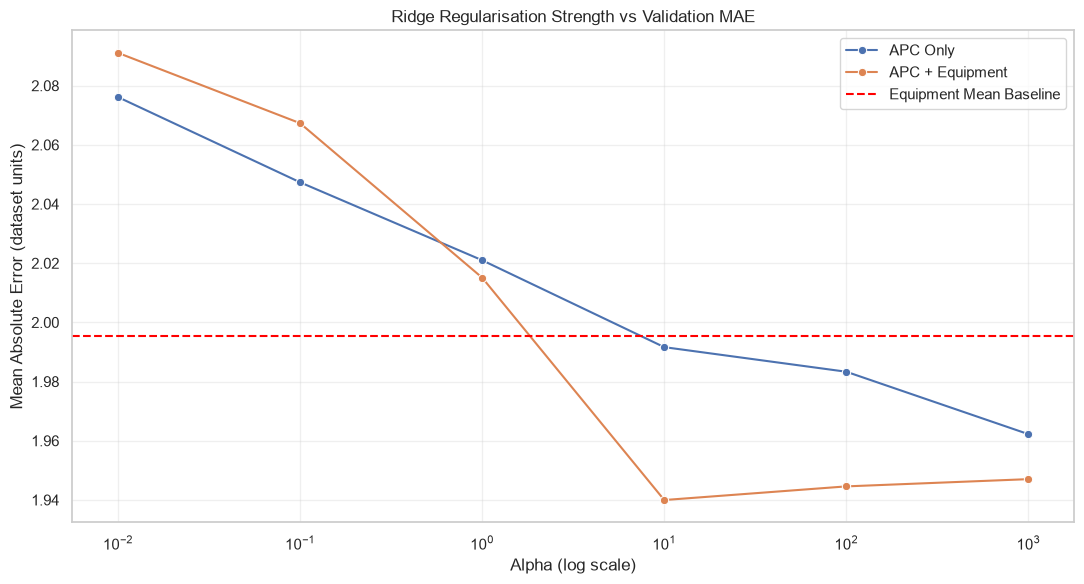

In [7]:

# STEP 3.2.10 - Ridge alpha comparison

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=ridge_results_df,
    x="Alpha",
    y="MAE",
    hue="Configuration",
    marker="o",
)

plt.axhline(
    BASELINE_MAE,
    color="red",
    linestyle="--",
    label="Equipment Mean Baseline",
)

plt.xscale("log")

plt.title(
    "Ridge Regularisation Strength vs Validation MAE"
)

plt.xlabel("Alpha (log scale)")
plt.ylabel("Mean Absolute Error (dataset units)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Model Performance Comparison

Compare ordinary Linear Regression and Ridge Regression
using validation MAE, RMSE, R2, MAPE, and prediction bias.

Select the lowest-MAE Ridge configuration for each
feature set and compare against the established baseline.

In [8]:

# STEP 3.2.11 - Compare all models

all_results = pd.concat(
    [
        linear_results_df,
        ridge_results_df,
    ],
    ignore_index=True,
)

all_results = (
    all_results
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(
    all_results.round(6)
)

best_ridge_per_config = (
    ridge_results_df
    .sort_values("MAE")
    .groupby(
        "Configuration",
        as_index=False,
    )
    .head(1)
)

comparison_results = pd.concat(
    [
        linear_results_df,
        best_ridge_per_config,
    ],
    ignore_index=True,
)

comparison_results = (
    comparison_results
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("\nBest model per primary experiment:")

display(
    comparison_results.round(6)
)

best_result = all_results.iloc[0]

best_model_name = best_result["Model"]

print("\nBest sensor-based model:")
print(best_model_name)

print(
    "Validation MAE:",
    round(best_result["MAE"], 6)
)

print(
    "Improvement over baseline:",
    round(
        best_result["MAE Improvement (%)"],
        4
    ),
    "%"
)

,Model,Algorithm,Configuration,Alpha,MAE,RMSE,R2,MAPE (%),Bias,Training Time (s),MAE Improvement (%)
0,"Ridge (APC + Equipment, alpha=10)",Ridge Regression,APC + Equipment,10.0,1.939950,13.921624,-31.488889,1.285926,-0.843021,0.088758,2.782740
1,"Ridge (APC + Equipment, alpha=100)",Ridge Regression,APC + Equipment,100.0,1.944563,12.272384,-24.247183,1.287490,-0.718743,0.109215,2.551572
2,"Ridge (APC + Equipment, alpha=1000)",Ridge Regression,APC + Equipment,1000.0,1.947010,7.661628,-8.840048,1.286868,-0.420021,0.102941,2.428925
3,"Ridge (APC Only, alpha=1000)",Ridge Regression,APC Only,1000.0,1.962206,7.617818,-8.727837,1.296932,-0.416048,0.083679,1.667424
4,"Ridge (APC Only, alpha=100)",Ridge Regression,APC Only,100.0,1.983303,12.220645,-24.034752,1.313292,-0.692679,0.084139,0.610150
5,"Ridge (APC Only, alpha=10)",Ridge Regression,APC Only,10.0,1.991619,14.299490,-33.276474,1.320337,-0.816917,0.085755,0.193433
6,"Ridge (APC + Equipment, alpha=1)",Ridge Regression,APC + Equipment,1.0,2.015104,15.130828,-37.377833,1.336455,-0.891449,0.374764,-0.983502
7,"Ridge (APC Only, alpha=1)",Ridge Regression,APC Only,1.0,2.020990,14.973313,-36.582948,1.340205,-0.855890,0.123225,-1.278472
8,"Ridge (APC Only, alpha=0.1)",Ridge Regression,APC Only,0.1,2.047337,15.591858,-39.752173,1.358021,-0.871753,0.197988,-2.598814
9,"Ridge (APC + Equipment, alpha=0.1)",Ridge Regression,APC + Equipment,0.1,2.067310,16.093749,-42.417967,1.371565,-0.925070,0.190206,-3.599706



Best model per primary experiment:


,Model,Algorithm,Configuration,Alpha,MAE,RMSE,R2,MAPE (%),Bias,Training Time (s),MAE Improvement (%)
0,"Ridge (APC + Equipment, alpha=10)",Ridge Regression,APC + Equipment,10.0,1.939950,13.921624,-31.488889,1.285926,-0.843021,0.088758,2.782740
1,"Ridge (APC Only, alpha=1000)",Ridge Regression,APC Only,1000.0,1.962206,7.617818,-8.727837,1.296932,-0.416048,0.083679,1.667424
2,Linear Regression (APC Only),Linear Regression,APC Only,None,2.136376,17.612816,-51.001110,1.417952,-0.984429,0.202019,-7.060847
3,Linear Regression (APC + Equipment),Linear Regression,APC + Equipment,None,2.155320,17.861044,-52.477206,1.430753,-1.024640,0.409504,-8.010193



Best sensor-based model:
Ridge (APC + Equipment, alpha=10)
Validation MAE: 1.93995
Improvement over baseline: 2.7827 %


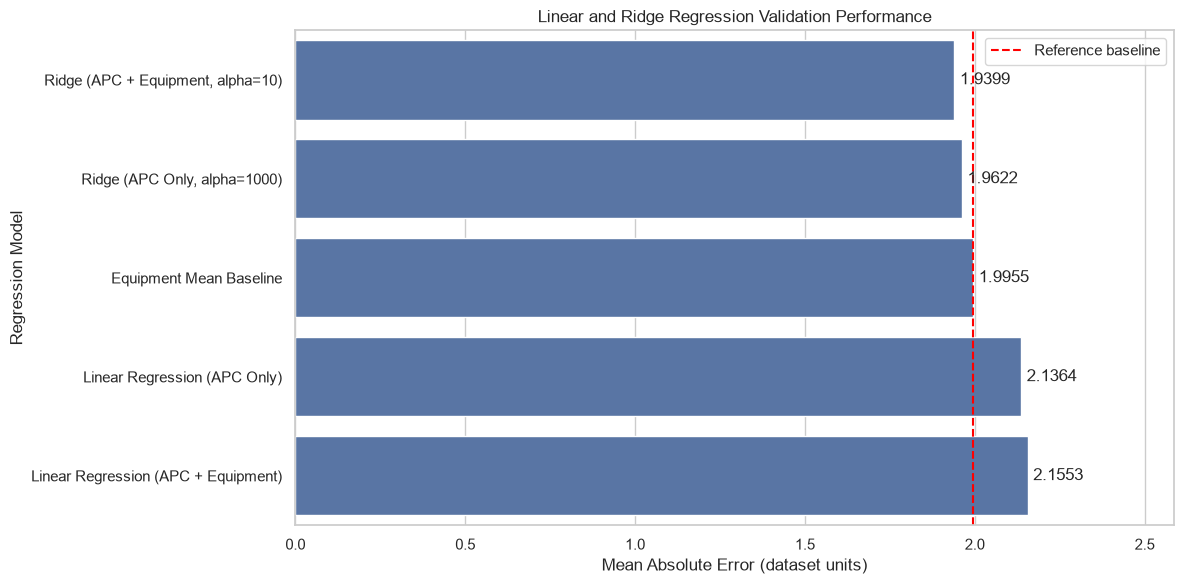

In [9]:

# Compare the four primary models with the baseline

plot_results = comparison_results[
    ["Model", "MAE"]
].copy()

baseline_row = pd.DataFrame([
    {
        "Model": "Equipment Mean Baseline",
        "MAE": BASELINE_MAE,
    }
])

plot_results = pd.concat(
    [plot_results, baseline_row],
    ignore_index=True,
).sort_values("MAE")

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=plot_results,
    x="MAE",
    y="Model",
)

ax.bar_label(
    ax.containers[0],
    fmt="%.4f",
    padding=4,
)

plt.axvline(
    BASELINE_MAE,
    color="red",
    linestyle="--",
    label="Reference baseline",
)

plt.xlim(
    0,
    plot_results["MAE"].max() * 1.2,
)

plt.title(
    "Linear and Ridge Regression Validation Performance"
)

plt.xlabel("Mean Absolute Error (dataset units)")
plt.ylabel("Regression Model")

plt.legend()
plt.tight_layout()
plt.show()

## 7. Prediction and Residual Analysis

Examine actual versus predicted film thickness
for the best sensor-based validation model.

Investigate residual distributions and systematic
overprediction or underprediction.

The selected model is a preliminary candidate,
not the final STRATUM model.

In [10]:

# STEP 3.2.12 - Retrieve the best candidate

all_trained_models = {
    **trained_linear_models,
    **trained_ridge_models,
}

best_pipeline = (
    all_trained_models[best_model_name]
)

best_predictions = (
    validation_predictions[best_model_name]
)

best_metrics = evaluate_regression(
    y_val,
    best_predictions,
)

print("Selected candidate:", best_model_name)

display(
    pd.DataFrame(
        [best_metrics]
    ).round(6)
)

Selected candidate: Ridge (APC + Equipment, alpha=10)


,MAE,RMSE,R2,MAPE (%),Bias
0,1.93995,13.921624,-31.488889,1.285926,-0.843021


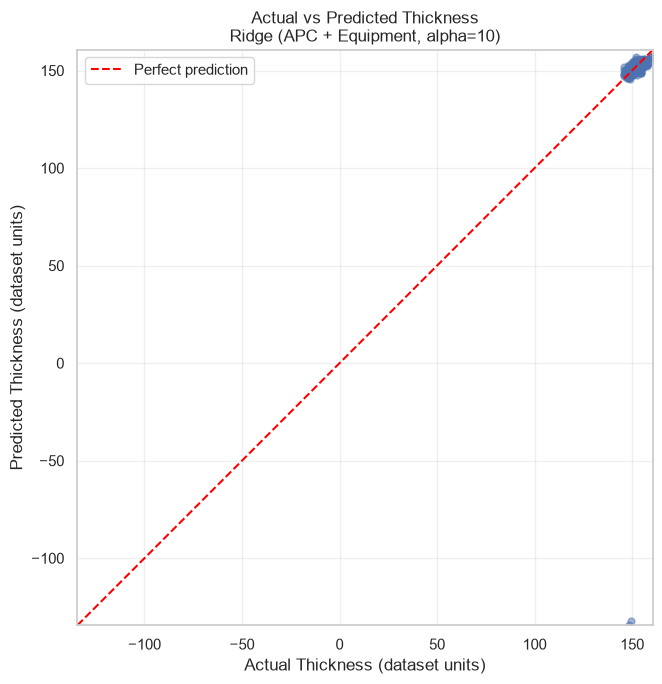

In [11]:

# Actual versus predicted values

lower = min(
    y_val.min(),
    best_predictions.min(),
)

upper = max(
    y_val.max(),
    best_predictions.max(),
)

plt.figure(figsize=(7, 7))

plt.scatter(
    y_val,
    best_predictions,
    alpha=0.5,
    s=25,
)

plt.plot(
    [lower, upper],
    [lower, upper],
    color="red",
    linestyle="--",
    label="Perfect prediction",
)

plt.xlim(lower, upper)
plt.ylim(lower, upper)

plt.gca().set_aspect(
    "equal",
    adjustable="box",
)

plt.title(
    f"Actual vs Predicted Thickness\n{best_model_name}"
)

plt.xlabel("Actual Thickness (dataset units)")
plt.ylabel("Predicted Thickness (dataset units)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

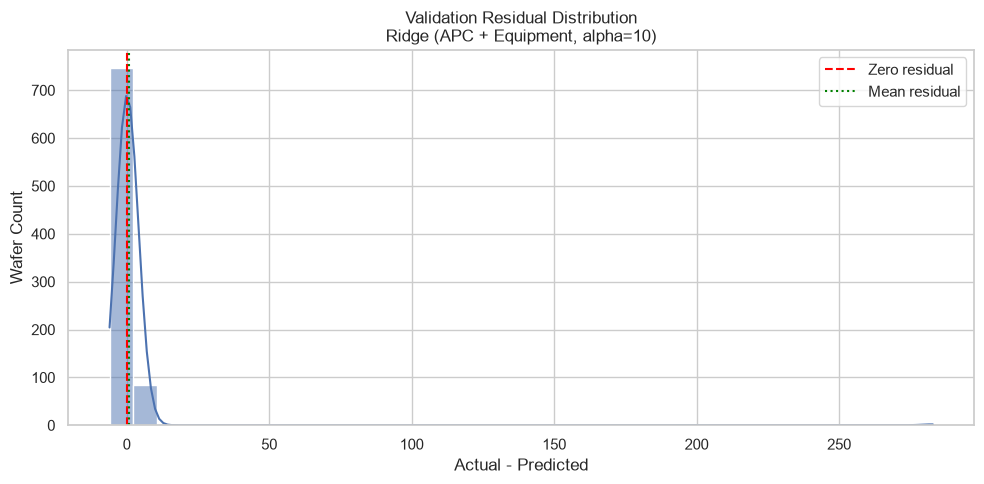

In [12]:

# Residual distribution

residuals = (
    y_val.to_numpy() - best_predictions
)

plt.figure(figsize=(10, 5))

sns.histplot(
    residuals,
    bins=35,
    kde=True,
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Zero residual",
)

plt.axvline(
    residuals.mean(),
    color="green",
    linestyle=":",
    label="Mean residual",
)

plt.title(
    f"Validation Residual Distribution\n{best_model_name}"
)

plt.xlabel("Actual - Predicted")
plt.ylabel("Wafer Count")

plt.legend()
plt.tight_layout()
plt.show()


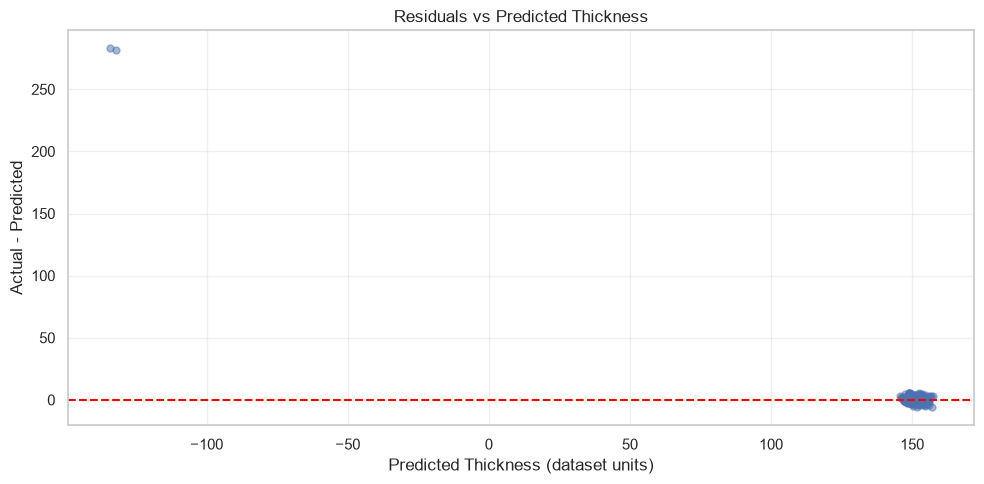

In [13]:

# Residuals versus predicted values

plt.figure(figsize=(10, 5))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.5,
    s=25,
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
)

plt.title(
    "Residuals vs Predicted Thickness"
)

plt.xlabel("Predicted Thickness (dataset units)")
plt.ylabel("Actual - Predicted")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Regression Coefficient Analysis

Inspect the coefficients of the selected linear-model
candidate.

Compare coefficient magnitudes after preprocessing.

Coefficients represent statistical associations within
the fitted model rather than causal manufacturing effects.

Correlated predictors and different feature encodings
limit direct physical interpretation.

In [14]:

# STEP 3.2.13 - Extract coefficients

coefficient_df = extract_linear_coefficients(
    best_pipeline
)

print(
    "Number of transformed coefficients:",
    len(coefficient_df)
)

display(
    coefficient_df.head(20).round(6)
)

Number of transformed coefficients: 173


,Feature,Coefficient,Absolute Coefficient
0,numeric__T_DEP1_PROCESS,5.448894,5.448894
1,numeric__OHM_TARGET_DEP1_A_A,-2.278749,2.278749
2,equipment__equipment_equipment_10,1.636337,1.636337
3,equipment__equipment_equipment_7,1.575202,1.575202
4,numeric__AMPS_TARGET_DEP1_A,-1.352754,1.352754
5,numeric__LIFE_SHIELDING_RUN_A,-1.347501,1.347501
6,numeric__DCBIAS_PLATEN_DEP1_I,-1.322815,1.322815
7,numeric__LIFE_TARGET_DEP1_S,-1.291597,1.291597
8,equipment__equipment_equipment_12,-1.277014,1.277014
9,equipment__equipment_equipment_13,-1.203420,1.203420


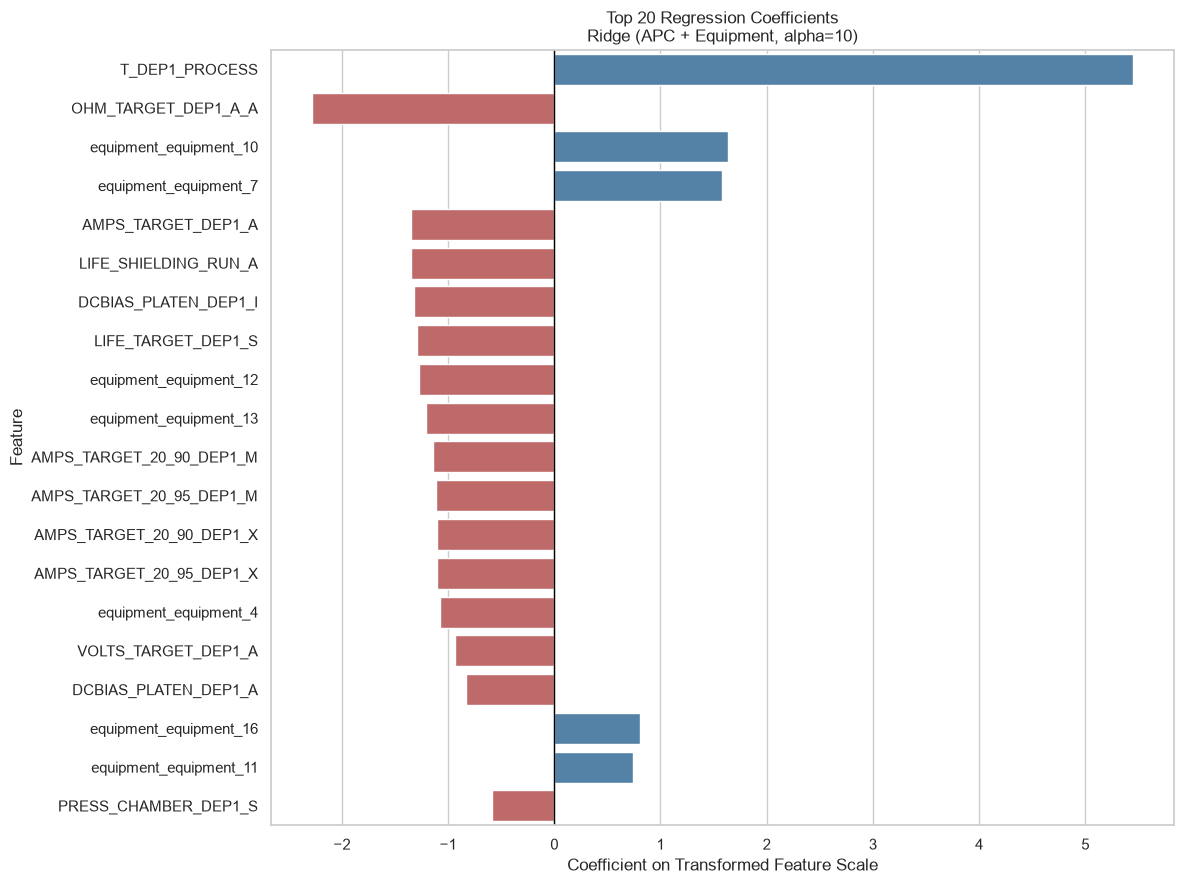

In [15]:

# Visualise selected regression coefficients

top_coefficients = (
    coefficient_df
    .head(20)
    .copy()
)

top_coefficients["Feature"] = (
    top_coefficients["Feature"]
    .str.replace(
        "numeric__",
        "",
        regex=False,
    )
    .str.replace(
        "equipment__",
        "",
        regex=False,
    )
)

plt.figure(figsize=(12, 9))

sns.barplot(
    data=top_coefficients,
    x="Coefficient",
    y="Feature",
    hue="Feature",
    legend=False,
    palette=[
        "steelblue" if value >= 0 else "indianred"
        for value in top_coefficients["Coefficient"]
    ],
)

plt.axvline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    f"Top 20 Regression Coefficients\n{best_model_name}"
)

plt.xlabel("Coefficient on Transformed Feature Scale")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## 9. Regularisation and Coefficient Magnitude

Compare coefficient L2 norms across Ridge alpha values.

Investigate the effect of regularisation on overall
coefficient magnitude within each feature configuration.

A smaller coefficient norm does not automatically
imply better prediction accuracy.

,Model,Configuration,Alpha,Coefficient L2 Norm
0,"Ridge (APC Only, alpha=0.01)",APC Only,0.01,28.322788
1,"Ridge (APC Only, alpha=0.1)",APC Only,0.10,17.184027
2,"Ridge (APC Only, alpha=1)",APC Only,1.00,10.857694
3,"Ridge (APC Only, alpha=10)",APC Only,10.00,7.453638
4,"Ridge (APC Only, alpha=100)",APC Only,100.00,4.140801
5,"Ridge (APC Only, alpha=1000)",APC Only,1000.00,1.258033
6,"Ridge (APC + Equipment, alpha=0.01)",APC + Equipment,0.01,29.073731
7,"Ridge (APC + Equipment, alpha=0.1)",APC + Equipment,0.10,15.489458
8,"Ridge (APC + Equipment, alpha=1)",APC + Equipment,1.00,11.150423
9,"Ridge (APC + Equipment, alpha=10)",APC + Equipment,10.00,7.991919


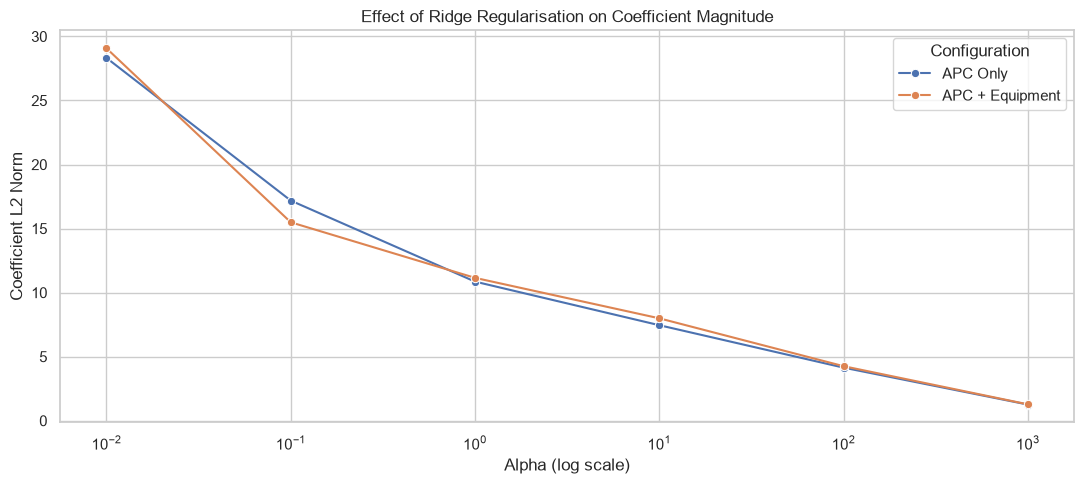

In [16]:

# STEP 3.2.14 - Coefficient shrinkage analysis

coefficient_norm_results = []

for _, row in ridge_results_df.iterrows():

    model_name = row["Model"]

    pipeline = trained_ridge_models[model_name]

    coefficients = (
        pipeline
        .named_steps["regressor"]
        .coef_
    )

    coefficient_norm_results.append({
        "Model": model_name,
        "Configuration": row["Configuration"],
        "Alpha": row["Alpha"],
        "Coefficient L2 Norm": float(
            np.linalg.norm(coefficients)
        ),
    })

coefficient_norm_df = pd.DataFrame(
    coefficient_norm_results
)

display(
    coefficient_norm_df.round(6)
)

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=coefficient_norm_df,
    x="Alpha",
    y="Coefficient L2 Norm",
    hue="Configuration",
    marker="o",
)

plt.xscale("log")

plt.title(
    "Effect of Ridge Regularisation on Coefficient Magnitude"
)

plt.xlabel("Alpha (log scale)")
plt.ylabel("Coefficient L2 Norm")

plt.tight_layout()
plt.show()

## 10. Equipment-Level Validation Error Analysis

Investigate whether sensor-based prediction errors
vary across equipment identifiers.

Compare sample counts, MAE, RMSE, and prediction bias.

Equipment-level differences do not establish
physical manufacturing faults.

In [17]:

# STEP 3.2.15 - Equipment-specific errors

equipment_errors = pd.DataFrame({
    "equipment": val_df["equipment"].to_numpy(),
    "actual": y_val.to_numpy(),
    "predicted": best_predictions,
})

equipment_errors["absolute_error"] = (
    equipment_errors["actual"]
    - equipment_errors["predicted"]
).abs()

equipment_errors["squared_error"] = (
    equipment_errors["actual"]
    - equipment_errors["predicted"]
) ** 2

equipment_errors["bias"] = (
    equipment_errors["predicted"]
    - equipment_errors["actual"]
)

equipment_error_summary = (
    equipment_errors
    .groupby("equipment")
    .agg(
        Records=("actual", "count"),
        MAE=("absolute_error", "mean"),
        MSE=("squared_error", "mean"),
        Bias=("bias", "mean"),
    )
)

equipment_error_summary["RMSE"] = np.sqrt(
    equipment_error_summary.pop("MSE")
)

equipment_error_summary = (
    equipment_error_summary[
        ["Records", "MAE", "RMSE", "Bias"]
    ]
    .sort_values("MAE", ascending=False)
)

display(
    equipment_error_summary.round(6)
)

,Records,MAE,RMSE,Bias
equipment,,,,
equipment_1,56,7.151776,37.721669,-6.858669
equipment_14,56,6.439459,37.843262,-5.880405
equipment_13,54,1.735481,1.982696,1.404242
equipment_11,50,1.693266,2.100094,-0.035415
equipment_3,47,1.381929,1.779847,-0.636612
equipment_16,47,1.372793,1.626729,1.196447
equipment_8,54,1.367971,1.678410,-0.842814
equipment_4,57,1.229103,1.664293,-0.386911
equipment_7,48,1.131550,1.540187,0.441844


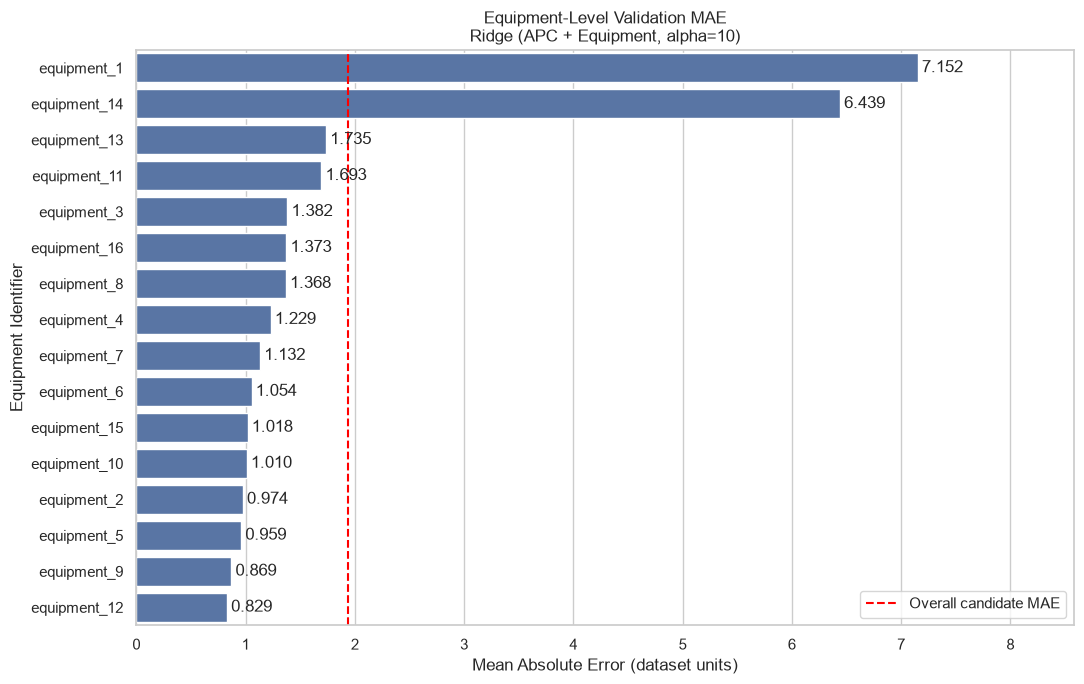

In [18]:

# Equipment-level validation MAE

plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=equipment_error_summary.reset_index(),
    x="MAE",
    y="equipment",
)

ax.axvline(
    best_metrics["MAE"],
    color="red",
    linestyle="--",
    label="Overall candidate MAE",
)

ax.bar_label(
    ax.containers[0],
    fmt="%.3f",
    padding=3,
)

plt.xlim(
    0,
    equipment_error_summary["MAE"].max() * 1.2,
)

plt.title(
    f"Equipment-Level Validation MAE\n{best_model_name}"
)

plt.xlabel("Mean Absolute Error (dataset units)")
plt.ylabel("Equipment Identifier")

plt.legend()
plt.tight_layout()
plt.show()


## 11. Experiment Result Preservation

Save Linear and Ridge Regression validation metrics,
feature configurations, regularisation parameters,
and experiment metadata.

No final test predictions or individual wafer
measurements are exported.

In [19]:

# STEP 3.2.16 - Save experiment results

results_dir = (
    project_root / "ml" / "results"
)

results_dir.mkdir(
    parents=True,
    exist_ok=True,
)

results_path = (
    results_dir / "thickness_linear_ridge.json"
)

# Convert NaN alpha values for ordinary Linear
# Regression into JSON-compatible null values.
serializable_results = (
    all_results
    .astype(object)
    .where(pd.notna(all_results), None)
    .to_dict(orient="records")
)

experiment_results = {
    "project": "STRATUM",
    "experiment": "thickness_linear_ridge",
    "target": TARGET,
    "dataset_sha256": current_sha256,
    "evaluation_partition": "validation",
    "training_records": len(train_df),
    "validation_records": len(val_df),
    "primary_metric": "MAE",
    "reference_baseline": (
        baseline_experiment["best_baseline"]
    ),
    "reference_baseline_mae": BASELINE_MAE,
    "feature_configurations": list(
        feature_configurations.keys()
    ),
    "ridge_alpha_values": alpha_values,
    "total_experiments": len(all_results),
    "best_sensor_model": best_model_name,
    "best_sensor_model_mae": float(
        best_result["MAE"]
    ),
    "best_sensor_model_improvement_pct": float(
        best_result["MAE Improvement (%)"]
    ),
    "results": serializable_results,
}

with open(
    results_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        experiment_results,
        file,
        indent=4,
        allow_nan=False,
    )

print("Experiment results saved successfully.")
print("ml/results/thickness_linear_ridge.json")

Experiment results saved successfully.
ml/results/thickness_linear_ridge.json


## 12. Pipeline Verification

Verify feature configuration behaviour, transformed
feature dimensions, prediction validity, and
unknown-equipment handling.

These are software integrity checks rather than
additional predictive-performance experiments.

In [20]:

# STEP 3.2.17 - Verify fitted pipelines

for model_name, pipeline in all_trained_models.items():

    predictions = validation_predictions[
        model_name
    ]

    assert len(predictions) == len(y_val)

    assert np.isfinite(predictions).all()

    preprocessor = pipeline.named_steps[
        "preprocessor"
    ]

    transformed_features = (
        preprocessor.get_feature_names_out()
    )

    coefficients = (
        pipeline.named_steps["regressor"].coef_
    )

    assert (
        len(transformed_features)
        == len(coefficients)
    )

    numeric_pipeline = (
        preprocessor.named_transformers_["numeric"]
    )

    assert "scaler" in numeric_pipeline.named_steps

    scaler = numeric_pipeline.named_steps["scaler"]

    assert np.all(
        np.asarray(scaler.n_samples_seen_)
        == len(train_df)
    )

    if "APC Only" in model_name:

        assert not any(
            name.startswith("equipment__")
            for name in transformed_features
        )

    else:

        assert any(
            name.startswith("equipment__")
            for name in transformed_features
        )

print("All fitted pipeline checks: PASSED")

print(
    "Total verified models:",
    len(all_trained_models)
)

All fitted pipeline checks: PASSED
Total verified models: 14


In [21]:

# Verify unknown-equipment prediction behaviour

equipment_model_name = (
    comparison_results.loc[
        comparison_results["Configuration"]
        == "APC + Equipment"
    ]
    .sort_values("MAE")
    .iloc[0]["Model"]
)

equipment_pipeline = (
    all_trained_models[equipment_model_name]
)

synthetic_input = (
    train_df[feature_columns]
    .iloc[[0]]
    .copy()
)

synthetic_input["equipment"] = (
    "equipment_unseen_demo"
)

synthetic_prediction = (
    equipment_pipeline.predict(
        synthetic_input
    )
)

assert synthetic_prediction.shape == (1,)

assert np.isfinite(
    synthetic_prediction
).all()

print("Unknown equipment prediction: PASSED")
print("Synthetic prediction:", synthetic_prediction[0])

Unknown equipment prediction: PASSED
Synthetic prediction: 154.98918135962654



## 13. Findings and Interpretation

### Model Development

Implemented reusable sensor-based Linear Regression
and Ridge Regression pipelines for virtual metrology.

Compared APC-only and APC-plus-equipment configurations.

### Preprocessing

- Training-only median imputation.
- Numeric missingness indicators.
- Numeric feature standardisation.
- Optional one-hot equipment encoding.
- End-to-end preprocessing and regression pipelines.

### Experiments

- Two ordinary Linear Regression models.
- Twelve Ridge Regression models.
- Six Ridge alpha values.
- Fourteen total sensor-based regression experiments.

### Reference Baseline

Equipment Mean Regressor:

Validation MAE: 1.995479 dataset units.

### Quantitative Results

Insert the actual results after notebook execution:

- Best ordinary Linear Regression model:
- Best APC-only Ridge alpha:
- Best APC-plus-equipment Ridge alpha:
- Best overall sensor-based candidate:
- Validation MAE:
- Validation RMSE:
- Validation R2:
- Validation MAPE:
- Validation prediction bias:
- Percentage MAE improvement over baseline:

### Equipment Metadata

Record whether equipment metadata improves validation
performance for Linear Regression and Ridge Regression.

### Regularisation Analysis

Record the relationship between alpha, validation MAE,
and coefficient magnitude.

### Residual Analysis

Record observations from actual-versus-predicted plots,
residual distributions, and residual-versus-prediction plots.

### Equipment-Level Performance

Record the equipment groups with the highest and lowest
validation MAE, considering the available sample counts.

### Limitations

- Linear models may not capture nonlinear relationships.
- Correlated sensors limit coefficient interpretation.
- Coefficients do not establish physical causality.
- Equipment-level errors do not establish machine faults.
- Validation metrics are used for model selection.
- Final test metrics have not been calculated.
- Historical full-dataset EDA preceded the fixed split.

### Conclusion

Sensor-based Linear Regression and Ridge Regression
have been developed and evaluated.

Their predictive usefulness must be assessed using
observed validation metrics rather than assumed
improvement over historical-average baselines.

The next step investigates nonlinear virtual metrology
using Random Forest Regression.